# 01 · The Chicken and the Egg

**Expectation-Maximization 101 — the algorithm that learns from data it cannot see.**

You are handed a single stream of numbers: the combined measurements of two
different populations mixed together — say the heights of two species, recorded
without labels. You are asked to recover the two populations: their means, their
spreads, and their proportions. You never saw which measurement came from which
species.

It looks impossible, because the information you need (the labels) is exactly the
information you do not have. Here is the bind, stated precisely:

- **If you knew the labels**, estimating each population's parameters would be trivial
  (just average the points in each group).
- **If you knew the parameters**, guessing the labels would be trivial (assign each
  point to the population it most likely came from).
- **You know neither.**

Expectation-maximization breaks the loop by *bootstrapping*: **guess** one, **fit**
the other as if the guess were true, then use the result to **re-guess**, and repeat.
That one idea is the whole algorithm. This notebook sets up the bind on a picture;
the rest of the series builds the loop from scratch.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def _repo_root() -> Path:
    here = Path.cwd()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").exists():
            return cand
    return here


ROOT = _repo_root()
FIG_DIR = ROOT / "outputs" / "figures"
DATA_DIR = ROOT / "outputs" / "data"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)


def _jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj


def savefig(fig, name):
    """Save a matplotlib figure as outputs/figures/<name>.png."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"figure -> {path.relative_to(ROOT)}")
    return path


def savejson(name, obj):
    """Save textual/numerical content as outputs/data/<name>.json."""
    path = DATA_DIR / f"{name}.json"
    path.write_text(json.dumps(_jsonable(obj), indent=2))
    print(f"data   -> {path.relative_to(ROOT)}")
    return path


plt.rcParams["figure.figsize"] = (7, 4.2)
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(42)


## The tangled data

Two Gaussian populations, mixed. This is **all you get to observe** — one pile of
numbers with no labels attached.


figure -> outputs/figures/nb01_tangled_data.png
data   -> outputs/data/nb01_inputs.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb01_inputs.json')

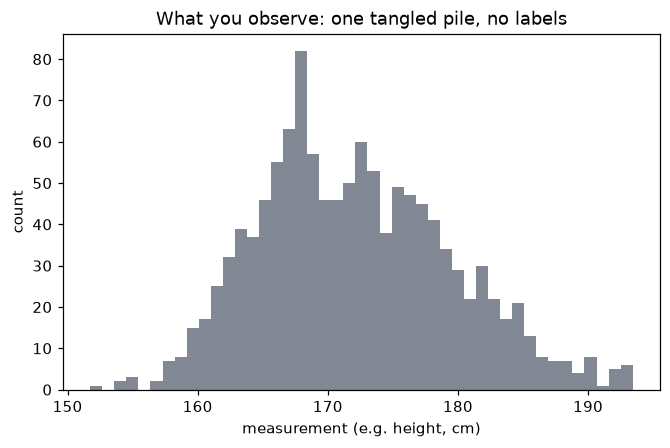

In [2]:
from src.datasets.mixtures import make_gaussian_mixture_1d

PLANTED = {
    "weights": [0.55, 0.45],
    "means": [168.0, 178.0],   # e.g. heights (cm) of two species
    "stds": [5.0, 6.0],
    "n_samples": 1200,
    "seed": 7,
}

x, true_labels, truth = make_gaussian_mixture_1d(
    PLANTED["n_samples"], PLANTED["weights"], PLANTED["means"], PLANTED["stds"],
    seed=PLANTED["seed"],
)

fig, ax = plt.subplots()
ax.hist(x, bins=45, color="#6b7280", alpha=0.85)
ax.set_xlabel("measurement (e.g. height, cm)")
ax.set_ylabel("count")
ax.set_title("What you observe: one tangled pile, no labels")
savefig(fig, "nb01_tangled_data")

savejson("nb01_inputs", {
    "description": "Planted 1-D two-population Gaussian mixture used in notebook 01.",
    "planted_truth": PLANTED,
})


## What you do *not* get to see

The same points, colored by the population that actually generated them. The two
humps overlap heavily — even with the labels the groups are not cleanly separable,
and we don't have the labels. This hidden coloring is precisely what EM will
reconstruct from the tangle above.


figure -> outputs/figures/nb01_hidden_truth.png


PosixPath('/workspaces/expectation_maximization_101/outputs/figures/nb01_hidden_truth.png')

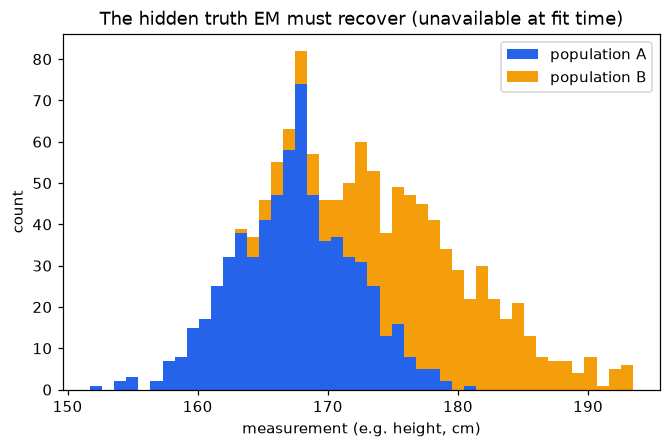

In [3]:
fig, ax = plt.subplots()
ax.hist([x[true_labels == 0], x[true_labels == 1]], bins=45, stacked=True,
        color=["#2563eb", "#f59e0b"], label=["population A", "population B"])
ax.set_xlabel("measurement (e.g. height, cm)")
ax.set_ylabel("count")
ax.set_title("The hidden truth EM must recover (unavailable at fit time)")
ax.legend()
savefig(fig, "nb01_hidden_truth")


## The bootstrap, as a teaser

Start from a deliberately *wild* guess and let the guess-then-fit loop run. Within a
handful of iterations the two populations separate out of the tangle and the recovered
parameters land close to the planted truth. We use the library's `GaussianMixtureEM`
here only to preview the payoff — notebook 03 builds this loop line by line.


figure -> outputs/figures/nb01_recovered_teaser.png
data   -> outputs/data/nb01_results.json
planted means : [168. 178.]
recovered means: [166.8  175.96]


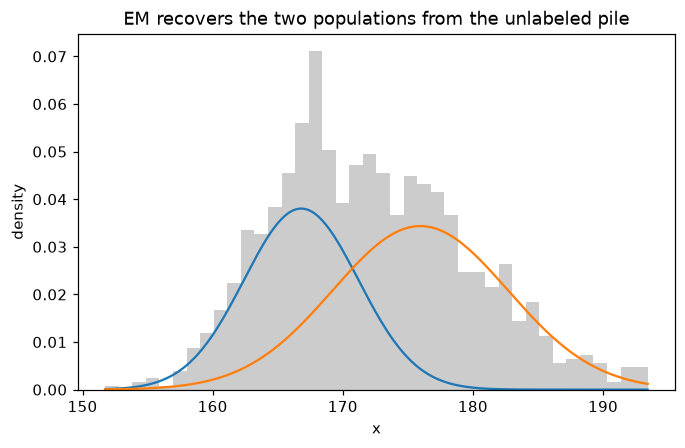

In [4]:
from src.em.gmm import GaussianMixtureEM
from src.visualisation import plot_gmm_1d

gmm = GaussianMixtureEM(2, n_init=1, init="random", random_state=0).fit(x.reshape(-1, 1))
rec_means = gmm.means_.ravel()
rec_stds = np.sqrt(gmm.covariances_.ravel())
order = np.argsort(rec_means)

fig, ax = plt.subplots()
plot_gmm_1d(x, gmm.weights_[order], rec_means[order], rec_stds[order], ax=ax)
ax.set_title("EM recovers the two populations from the unlabeled pile")
savefig(fig, "nb01_recovered_teaser")

results = {
    "planted": {"means": PLANTED["means"], "stds": PLANTED["stds"], "weights": PLANTED["weights"]},
    "recovered": {
        "means": rec_means[order],
        "stds": rec_stds[order],
        "weights": gmm.weights_[order],
    },
    "n_iterations": gmm.n_iter_,
    "final_log_likelihood": gmm.log_likelihood_,
    "loglik_history": gmm.loglik_history_,
}
savejson("nb01_results", results)
print("planted means :", np.round(PLANTED["means"], 2))
print("recovered means:", np.round(np.sort(rec_means), 2))


## The one sentence that is all of EM

> Guess the hidden labels, fit the model as if the guess were true, use the new model
> to re-guess the labels, and repeat until nothing changes.

It provably never makes the fit worse (the log-likelihood climbs every iteration), it
recovers structure from data that never carried labels, and — as the next notebooks
show — it is the same loop hiding inside Gaussian mixtures, K-Means, latent class
analysis, and principled missing-data imputation.

**Next:** `02_two_coins` — the same loop at its most transparent, traced by hand.


In [5]:
savejson("nb01_narrative", {
    "title": "The Chicken and the Egg",
    "thesis": (
        "EM is a two-step loop (E: guess soft labels; M: fit as if true; repeat) that "
        "provably never lowers the likelihood and recovers populations never observed separately."
    ),
    "the_bind": [
        "If you knew the labels, estimating the parameters would be trivial.",
        "If you knew the parameters, guessing the labels would be trivial.",
        "You know neither.",
    ],
    "the_resolution": "Bootstrap: guess one, fit the other as if true, re-guess, repeat.",
    "figures": {
        "nb01_tangled_data": "The observed, unlabeled mixture.",
        "nb01_hidden_truth": "The hidden component labels EM must recover.",
        "nb01_recovered_teaser": "EM recovering the two populations from the tangle.",
    },
})


data   -> outputs/data/nb01_narrative.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb01_narrative.json')